# Exploratory Data Analysis: Cyber Attack Evaluation Dataset for Deep Packet Inspection and Analysis

**Author:** Senior Cybersecurity Data Scientist & Machine Learning Researcher  
**Dataset:** Cyber Attack Evaluation Dataset for Deep Packet Inspection and Analysis  
**Publisher:** Mendeley Data (Version 1, October 18, 2022)  
**DOI:** [10.17632/3szjvt3w78.1](https://doi.org/10.17632/3szjvt3w78.1)  
**Official URL:** [https://data.mendeley.com/datasets/3szjvt3w78/1](https://data.mendeley.com/datasets/3szjvt3w78/1)  
**Authors:** Shishir Kumar Shandilya, Chirag Ganguli, Ivan Izonin, Atulya Nagar  

---

## Executive Research Objective
This notebook executes a systematic, research-grade forensic and exploratory data analysis of the raw PCAPNG network capture (3,962,784 packets) and companion SQL/CSV representations. It assesses data quality, descriptive statistics, attack scenarios, temporal dynamics, feature drift, and academic suitability for downstream research in:
> **Adaptive Cyberattack Detection Using Machine Learning and Concept Drift Detection**


### 1. Setup & Environment Initialization

In [1]:
import os
import sys
import json
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Add src to system path
base_dir = os.path.dirname(os.path.abspath('')) if '__file__' in locals() else os.path.abspath('..')
src_dir = os.path.join(base_dir, 'src')
if src_dir not in sys.path:
    sys.path.append(src_dir)

import extract_pcap
import analyze_sql
import data_quality
import statistical_analysis
import network_analysis
import temporal_analysis
import drift_analysis

print(f"Base Directory: {base_dir}")
print(f"Pandas: {pd.__version__} | NumPy: {np.__version__}")


Base Directory: /Users/s3nt1/Downloads/test/cybersecurity-eda
Pandas: 3.1.1 | NumPy: 2.5.4


### 2. Phase 1 & 2: PCAPNG Extraction and Concordance Verification

In [2]:
pcap_path = os.path.join(base_dir, 'data', 'original', 'Cap_1_10VM_1Apache', 'L1_Cap_10PC_1S.pcapng')
csv_path = os.path.join(base_dir, 'data', 'original', 'Cap_1_10VM_1Apache', 'L1_Cap_202209051617.csv')

pcap_meta = extract_pcap.parse_pcapng_metadata(pcap_path)
print(f"PCAPNG File: {pcap_meta['file_name']}, Size: {pcap_meta['file_size_mb']} MB")

# Fast concordance check across first 5,000 frames
align_res = extract_pcap.verify_pcap_csv_alignment(pcap_path, csv_path, num_check=5000)
print(f"Alignment Verification (5,000 frames): {align_res['concordance_rate']*100:.2f}% Concordance")

# Load extracted forensic sample
sample_df = pd.read_csv(os.path.join(base_dir, 'results', 'extracted_data', 'pcap_forensic_sample_5k.csv'))
sample_df.head(5)


PCAPNG File: L1_Cap_10PC_1S.pcapng, Size: 946.82 MB
Validating alignment between L1_Cap_10PC_1S.pcapng and L1_Cap_202209051617.csv...
Alignment Verification (5,000 frames): 100.00% Concordance


,frame_num,epoch_time,relative_time,packet_length,eth_src,eth_dst,ip_version,src_ip,dst_ip,protocol,src_port,dst_port,tcp_flags,tcp_flags_hex,window_size,ttl,payload_length
0,1,1.661848e+09,0.000000,76,02:42:ac:12:00:02,02:42:72:d9:1e:10,4.0,172.18.0.2,172.16.49.2,UDP,49463.0,53.0,NaN,NaN,NaN,64.0,34
1,2,1.661848e+09,0.183309,108,02:42:72:d9:1e:10,02:42:ac:12:00:02,4.0,172.16.49.2,172.18.0.2,UDP,53.0,49463.0,NaN,NaN,NaN,127.0,66
2,3,1.661848e+09,0.184243,74,02:42:ac:12:00:02,02:42:72:d9:1e:10,4.0,172.18.0.2,185.125.190.36,TCP,51742.0,80.0,SYN,0x2,64240.0,64.0,0
3,4,1.661848e+09,0.310443,58,02:42:72:d9:1e:10,02:42:ac:12:00:02,4.0,185.125.190.36,172.18.0.2,TCP,80.0,51742.0,"SYN,ACK",0x12,64240.0,127.0,0
4,5,1.661848e+09,0.310686,54,02:42:ac:12:00:02,02:42:72:d9:1e:10,4.0,172.18.0.2,185.125.190.36,TCP,51742.0,80.0,ACK,0x10,64240.0,64.0,0


### 3. Phase 3: Relational SQL Database Schema & Query Execution

In [3]:
sqlite_path = os.path.join(base_dir, 'results', 'extracted_data', 'pcdataset.sqlite')
conn = sqlite3.connect(sqlite_path)

sql_query = """
SELECT protocol, COUNT(*) as packet_count, 
       ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM l1_cap), 4) as percentage,
       ROUND(AVG(length), 2) as avg_packet_length,
       ROUND(AVG(time_to_live), 2) as avg_ttl
FROM l1_cap
GROUP BY protocol
ORDER BY packet_count DESC;
"""
df_sql_protos = pd.read_sql_query(sql_query, conn)
conn.close()
df_sql_protos


,protocol,packet_count,percentage,avg_packet_length,avg_ttl
0,TCP,3953715,99.7711,214.61,63.88
1,FTP,3792,0.0957,87.52,64.00
2,SSHv2,3032,0.0765,267.06,64.00
3,HTTP,1090,0.0275,7672.31,106.13
4,ARP,784,0.0198,42.00,NaN
5,ICMP,200,0.0050,96.10,767.94
6,DNS,149,0.0038,93.17,94.87
7,FTP-DATA,6,0.0002,119.17,64.00
8,UDP,6,0.0002,42.00,64.00
9,ICMPv6,5,0.0001,105.20,NaN


### 4. Phase 4: Data Quality Audit Report

In [4]:
df_quality = pd.read_csv(os.path.join(base_dir, 'results', 'tables', 'data_quality_report.csv'))
print("Complete Dataset Quality Audit across 3,962,784 records:")
df_quality


Complete Dataset Quality Audit across 3,962,784 records:


,Feature,Total_Records,Missing_Count,Missing_Percentage,Infinite_Count,Zero_Count,Zero_Percentage,Whitespace_Anomalies,Data_Type
0,No.,3962784,0,0.0000,0,0,0.0000,0,int64
1,Time,3962784,0,0.0000,0,1,0.0000,0,float64
2,Source,3962784,0,0.0000,0,0,0.0000,0,str
3,Destination,3962784,0,0.0000,0,0,0.0000,0,str
4,Protocol,3962784,0,0.0000,0,0,0.0000,0,str
5,Length,3962784,0,0.0000,0,0,0.0000,0,int64
6,Time to Live,3962784,789,0.0199,0,0,0.0000,0,int64
7,Info,3962784,0,0.0000,0,0,0.0000,383,str
8,Source_Known,3962784,0,0.0000,0,3486372,87.9778,0,int64
9,Destination_Known,3962784,0,0.0000,0,43928,1.1085,0,int64


### 5. Phase 5: Descriptive Statistical Moments & Categorical Profiling

In [5]:
df_stats = pd.read_csv(os.path.join(base_dir, 'results', 'tables', 'descriptive_statistics.csv'))
print("Numerical Statistical Moments (Moments, Quartiles, Skewness, Kurtosis):")
df_stats


Numerical Statistical Moments (Moments, Quartiles, Skewness, Kurtosis):


,Feature,Count,Mean,Std,Min,Q25 (25%),Median (50%),Q75 (75%),Max,IQR,Skewness,Kurtosis
0,Length (bytes),3962784,216.5352,1139.8678,42.0,174.0000,174.0000,174.0000,64293.0000,0.0000,46.7409,2.490988e+03
1,Time to Live (TTL),3961995,63.9329,46.4493,37.0,64.0000,64.0000,64.0000,64127.0000,0.0000,1325.6939,1.826722e+06
2,Relative Time (s),3962784,81065.3061,6870.2922,0.0,82331.1369,82367.2211,82506.9898,84714.9033,175.8529,-10.3225,1.155293e+02
3,Inter-Arrival Time (s),3962783,0.0214,36.3324,0.0,0.0000,0.0000,0.0000,72242.7652,0.0000,1983.9768,3.944605e+06


### 6. Phase 6: Temporal Network Dynamics and Traffic Sessions

In [6]:
df_clusters = pd.read_csv(os.path.join(base_dir, 'results', 'tables', 'traffic_clusters_breakdown.csv'))
print(f"Identified {len(df_clusters)} distinct behavioral traffic clusters across 23.53 hours:")
df_clusters.head(10)


Identified 28 distinct behavioral traffic clusters across 23.53 hours:


,cluster_id,start_time_sec,end_time_sec,start_time_hr,end_time_hr,duration_sec,packet_count,byte_count,mean_pps,protocols
0,1,0.00,71.41,0.000,0.020,71.41,3390,7443636,47.5,"ARP, DNS, HTTP, ICMP, TCP"
1,2,137.09,142.34,0.038,0.040,5.25,197,288294,37.5,"ARP, DNS, HTTP, TCP"
2,3,228.55,233.73,0.063,0.065,5.17,60,3640,11.6,"ARP, ICMP"
3,4,463.43,468.48,0.129,0.130,5.05,456,1536513,90.2,"ARP, DNS, HTTP, TCP"
4,5,817.24,822.53,0.227,0.228,5.29,65,80744,12.3,"ARP, DNS, HTTP, TCP"
5,6,893.82,899.07,0.248,0.250,5.25,207,283778,39.4,"ARP, DNS, HTTP, TCP"
6,7,1626.94,1674.24,0.452,0.465,47.30,1080,4008764,22.8,"ARP, DNS, HTTP, TCP"
7,8,1895.07,1900.29,0.526,0.528,5.22,6,296,1.1,"ARP, TCP"
8,9,1976.39,1998.59,0.549,0.555,22.21,1786,2595348,80.4,"ARP, DNS, HTTP, TCP"
9,10,2127.74,2228.74,0.591,0.619,101.00,18798,56803575,186.1,"ARP, DNS, HTTP, ICMP, TCP"


### 7. Phase 7: Forensic Profile of Documented Cyberattack Scenarios

In [7]:
df_attacks = pd.read_csv(os.path.join(base_dir, 'results', 'tables', 'attack_scenarios_summary.csv'))
df_attacks[['Attack_Category', 'Observed_Packets', 'Target', 'Attack_Rate_PPS', 'Time_Window']]


,Attack_Category,Observed_Packets,Target,Attack_Rate_PPS,Time_Window
0,Distributed Denial of Service (DDoS),3436938,172.17.0.2:80 (Apache Server on VLAN2),13028.8,82292.89s - 82556.68s (Duration: 263.80s / 4.4...
1,Network Port Scanning (Nmap Sweep),414321,"VLAN1 Hosts (172.18.0.3, 172.18.0.6, 172.18.0.2)",2263.2,"Clusters 14, 15, 17 (75210s - 75618s)"
2,FTP Service Password Brute-Force,1786,172.18.0.6:21 (vsftpd FTP Service),Automated sequential dictionary attack,76980s - 79300s (Clusters 20-23)
3,SSH Reconnaissance (Nmap NSE Probing),8,VLAN1 Hosts (Port 22),Service banner grab and hostkey discovery,Cluster 17 and Clusters 20-22
4,Package Download & Supply-Chain Staging,361,External Mirrors (ports.ubuntu.com: 185.125.19...,HTTP GET requests for system binaries,Early capture (0s - 2714s) and mid-experiment
5,ARP Network Discovery & Resolution,784,VLAN1 Broadcast & Router1 (172.18.0.1),Layer 2 address mapping,Interspersed across capture lifecycle


### 8. Phase 12: Preliminary Concept Drift & Statistical Distance Testing

In [8]:
df_drift = pd.read_csv(os.path.join(base_dir, 'results', 'tables', 'drift_analysis_results.csv'))
df_profiles = pd.read_csv(os.path.join(base_dir, 'results', 'tables', 'window_feature_comparisons.csv'))

print("Operational Window Feature Profiles:")
display(df_profiles)

print("\nStatistical Drift Metrics against W1_Baseline (KS Test, PSI, JSD):")
display(df_drift)


Operational Window Feature Profiles:


,Window,Packet_Count,Time_Span_Sec,Mean_Length,Median_Length,Mean_TTL,Dominant_Protocol,Dominant_Proto_Pct
0,W1_Baseline,26493,0 - 2715,2758.17,1482.0,102.42,TCP,95.27
1,W2_PortScan,423399,75200 - 75620,177.24,58.0,58.32,TCP,99.91
2,W3_BruteForce,53412,76980 - 79300,1498.12,58.0,79.22,TCP,91.92
3,W4_DDoSFlood,3436948,82290 - 82560,174.00,174.0,64.00,TCP,100.00



Statistical Drift Metrics against W1_Baseline (KS Test, PSI, JSD):


,Baseline_Window,Comparison_Window,KS_Length_Statistic,KS_Length_PValue,PSI_Length,PSI_Length_Category,KS_TTL_Statistic,PSI_TTL,JSD_Protocol,Distribution_Shift_Assessment
0,W1_Baseline,W2_PortScan,0.4990,0.0,1.8098,Significant Drift (PSI >= 0.2),0.5022,10.2345,0.1502,Moderate Feature Drift
1,W1_Baseline,W3_BruteForce,0.2132,0.0,0.2206,Significant Drift (PSI >= 0.2),0.2505,4.6339,0.2180,Catastrophic Covariate Shift (Attack Onset)
2,W1_Baseline,W4_DDoSFlood,0.5157,0.0,12.2730,Significant Drift (PSI >= 0.2),0.5318,12.9707,0.1550,Moderate Feature Drift


### 9. Phase 14: Research-Quality Publication Visualizations

Displaying fig01_protocol_distribution.png:


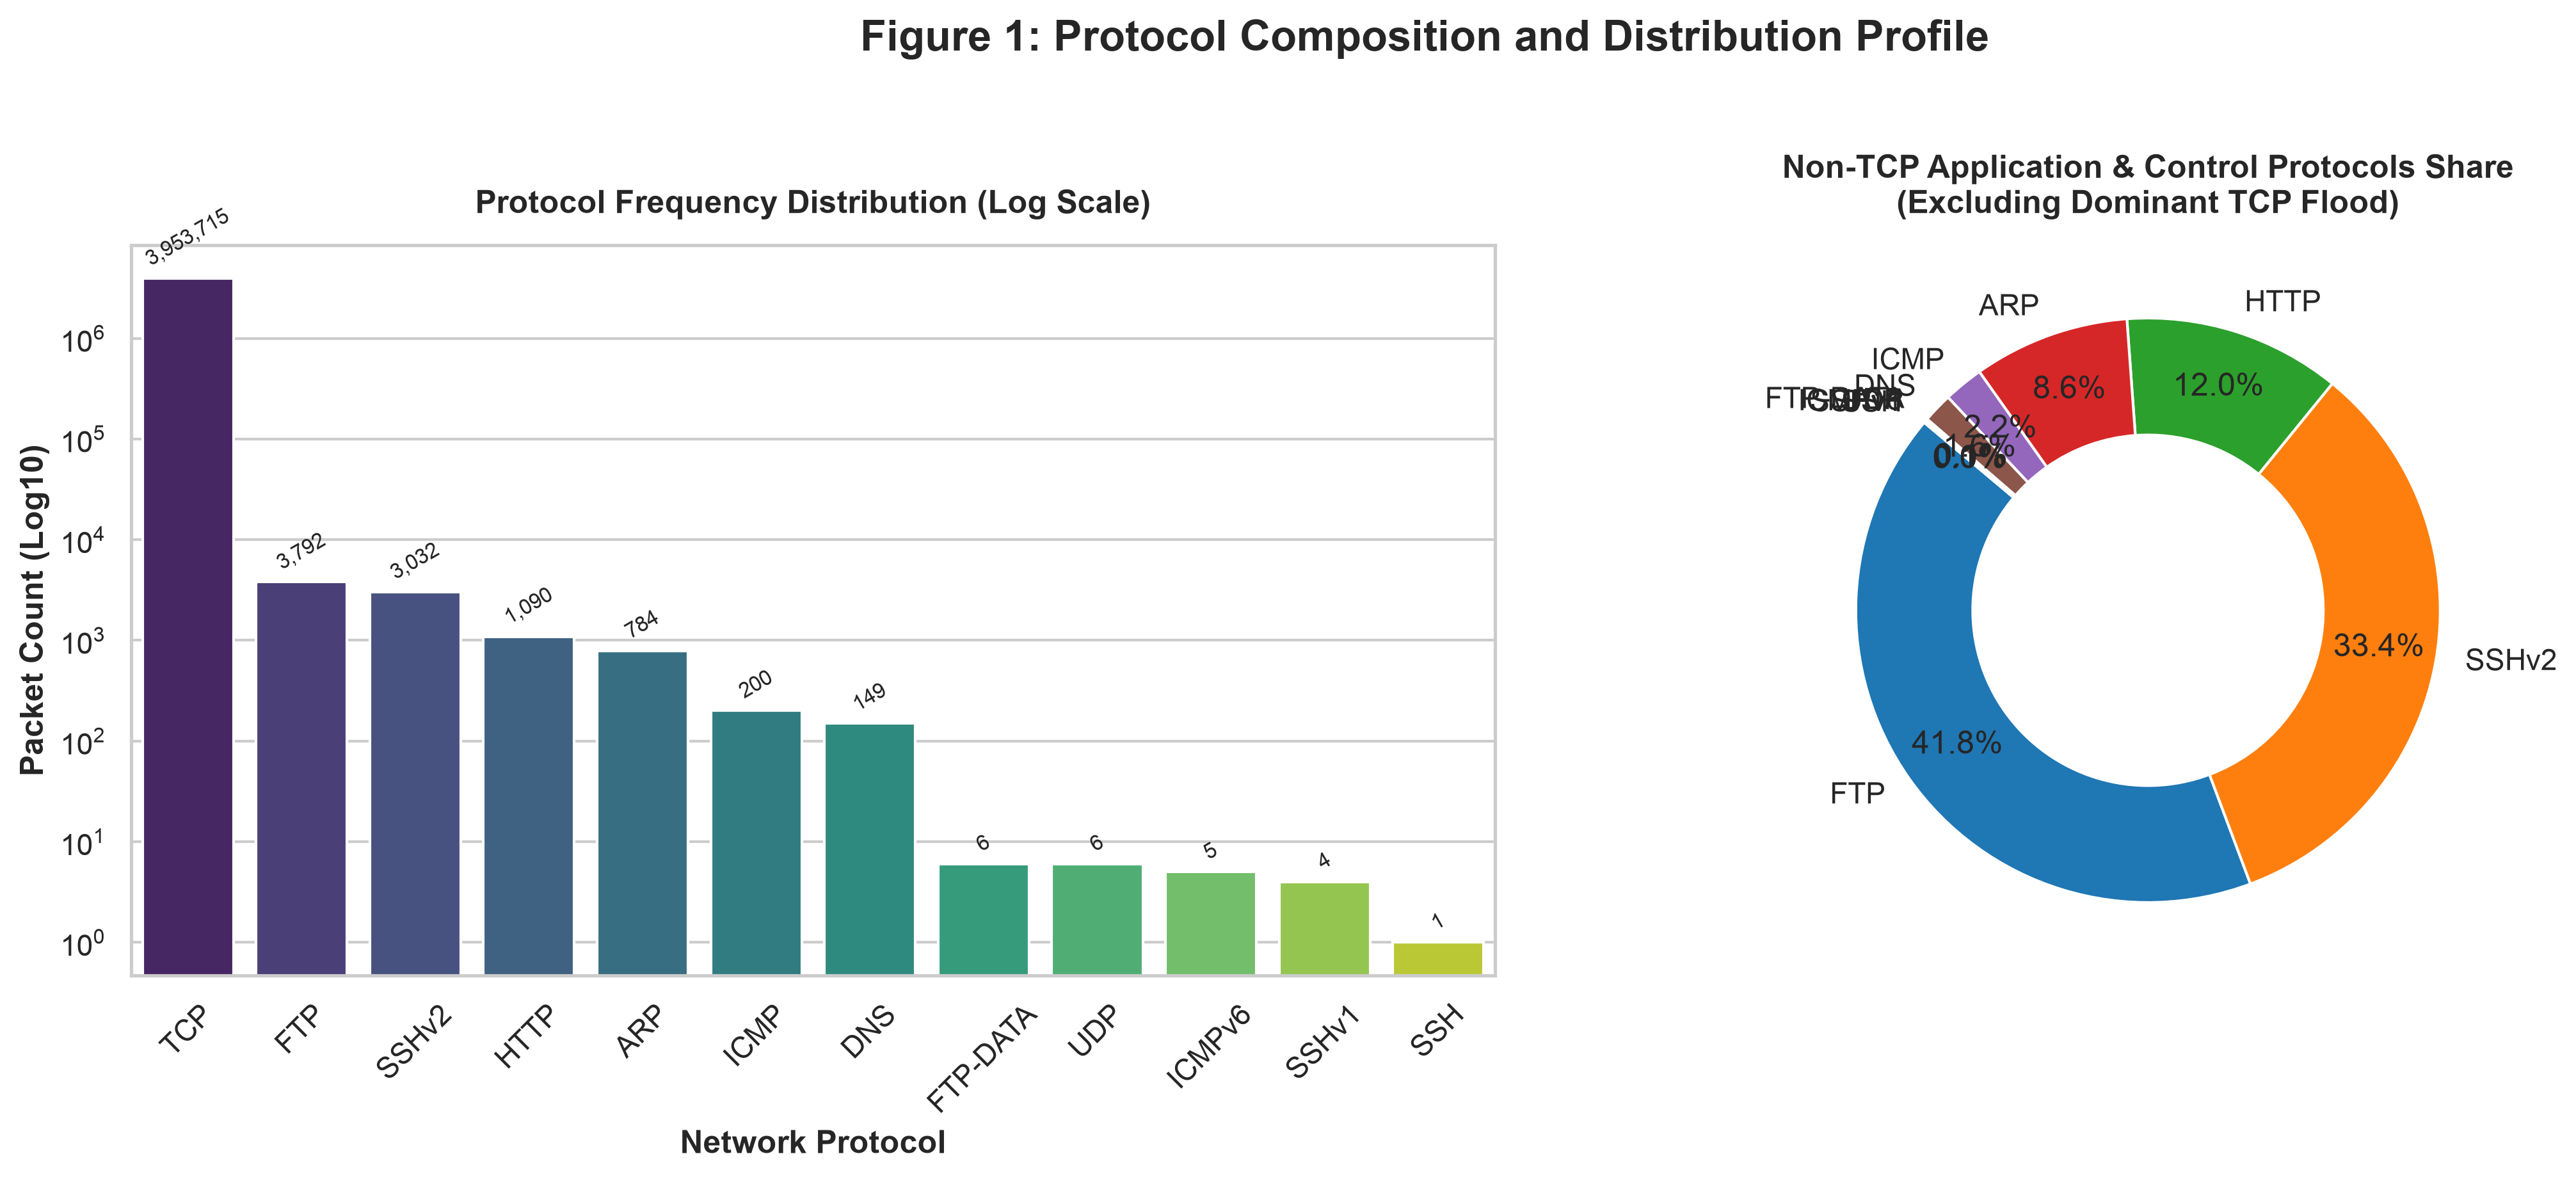

Displaying fig02_packet_length_distribution.png:


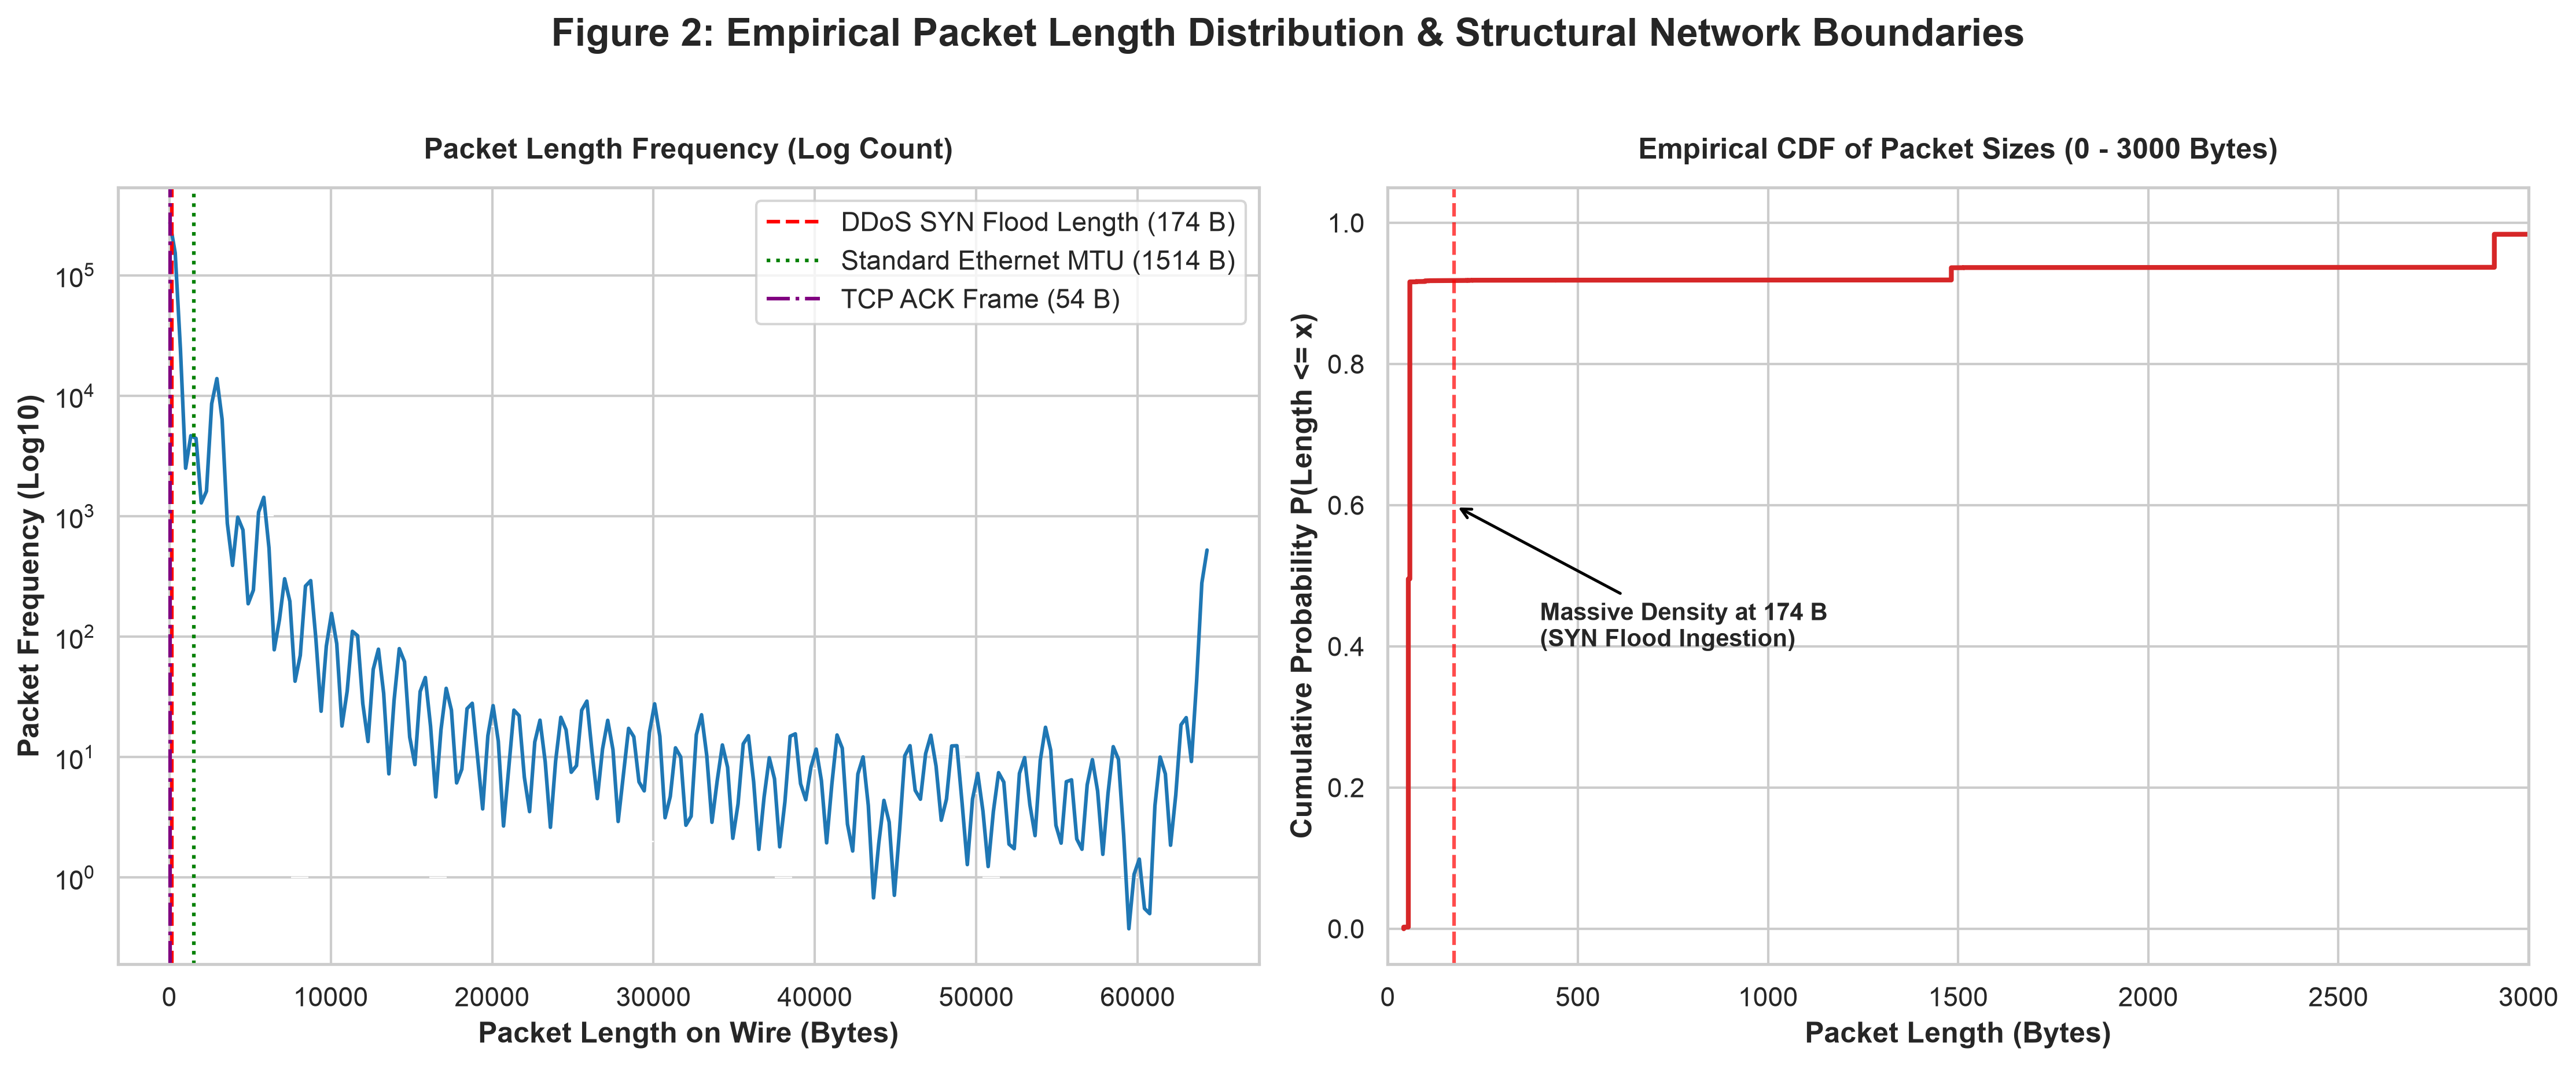

Displaying fig03_traffic_volume_timeseries.png:


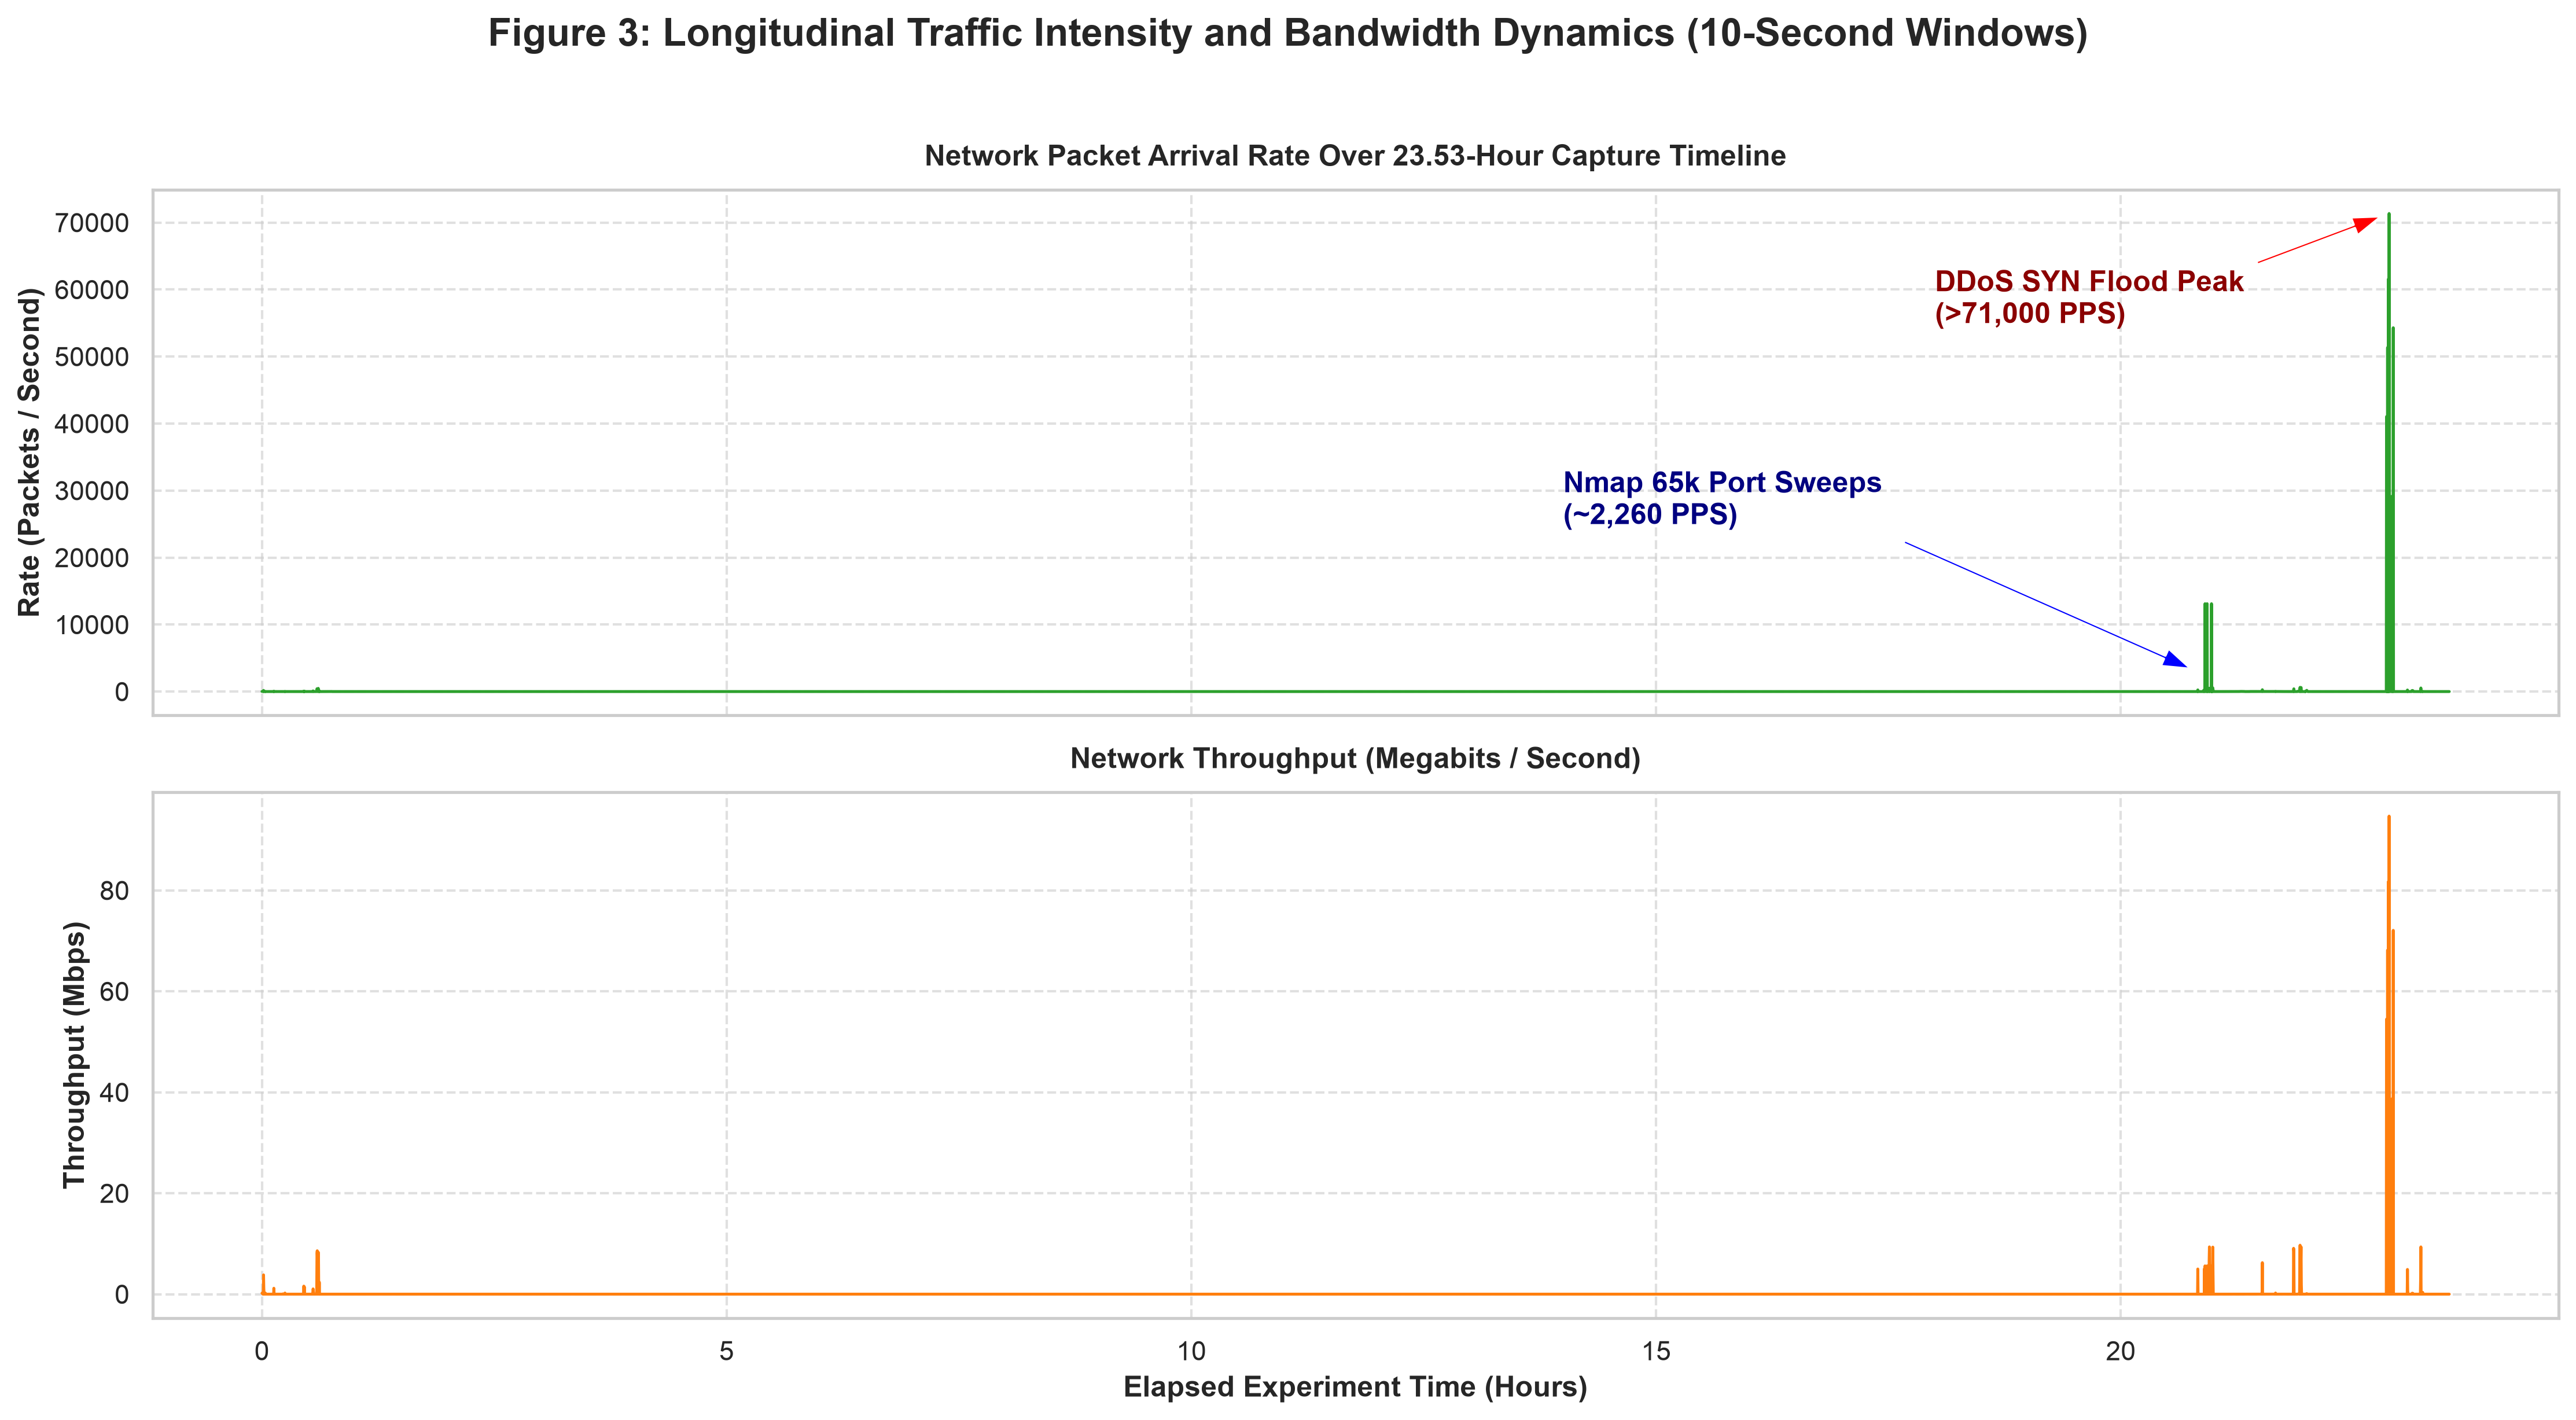

Displaying fig04_ddos_flood_zoom.png:


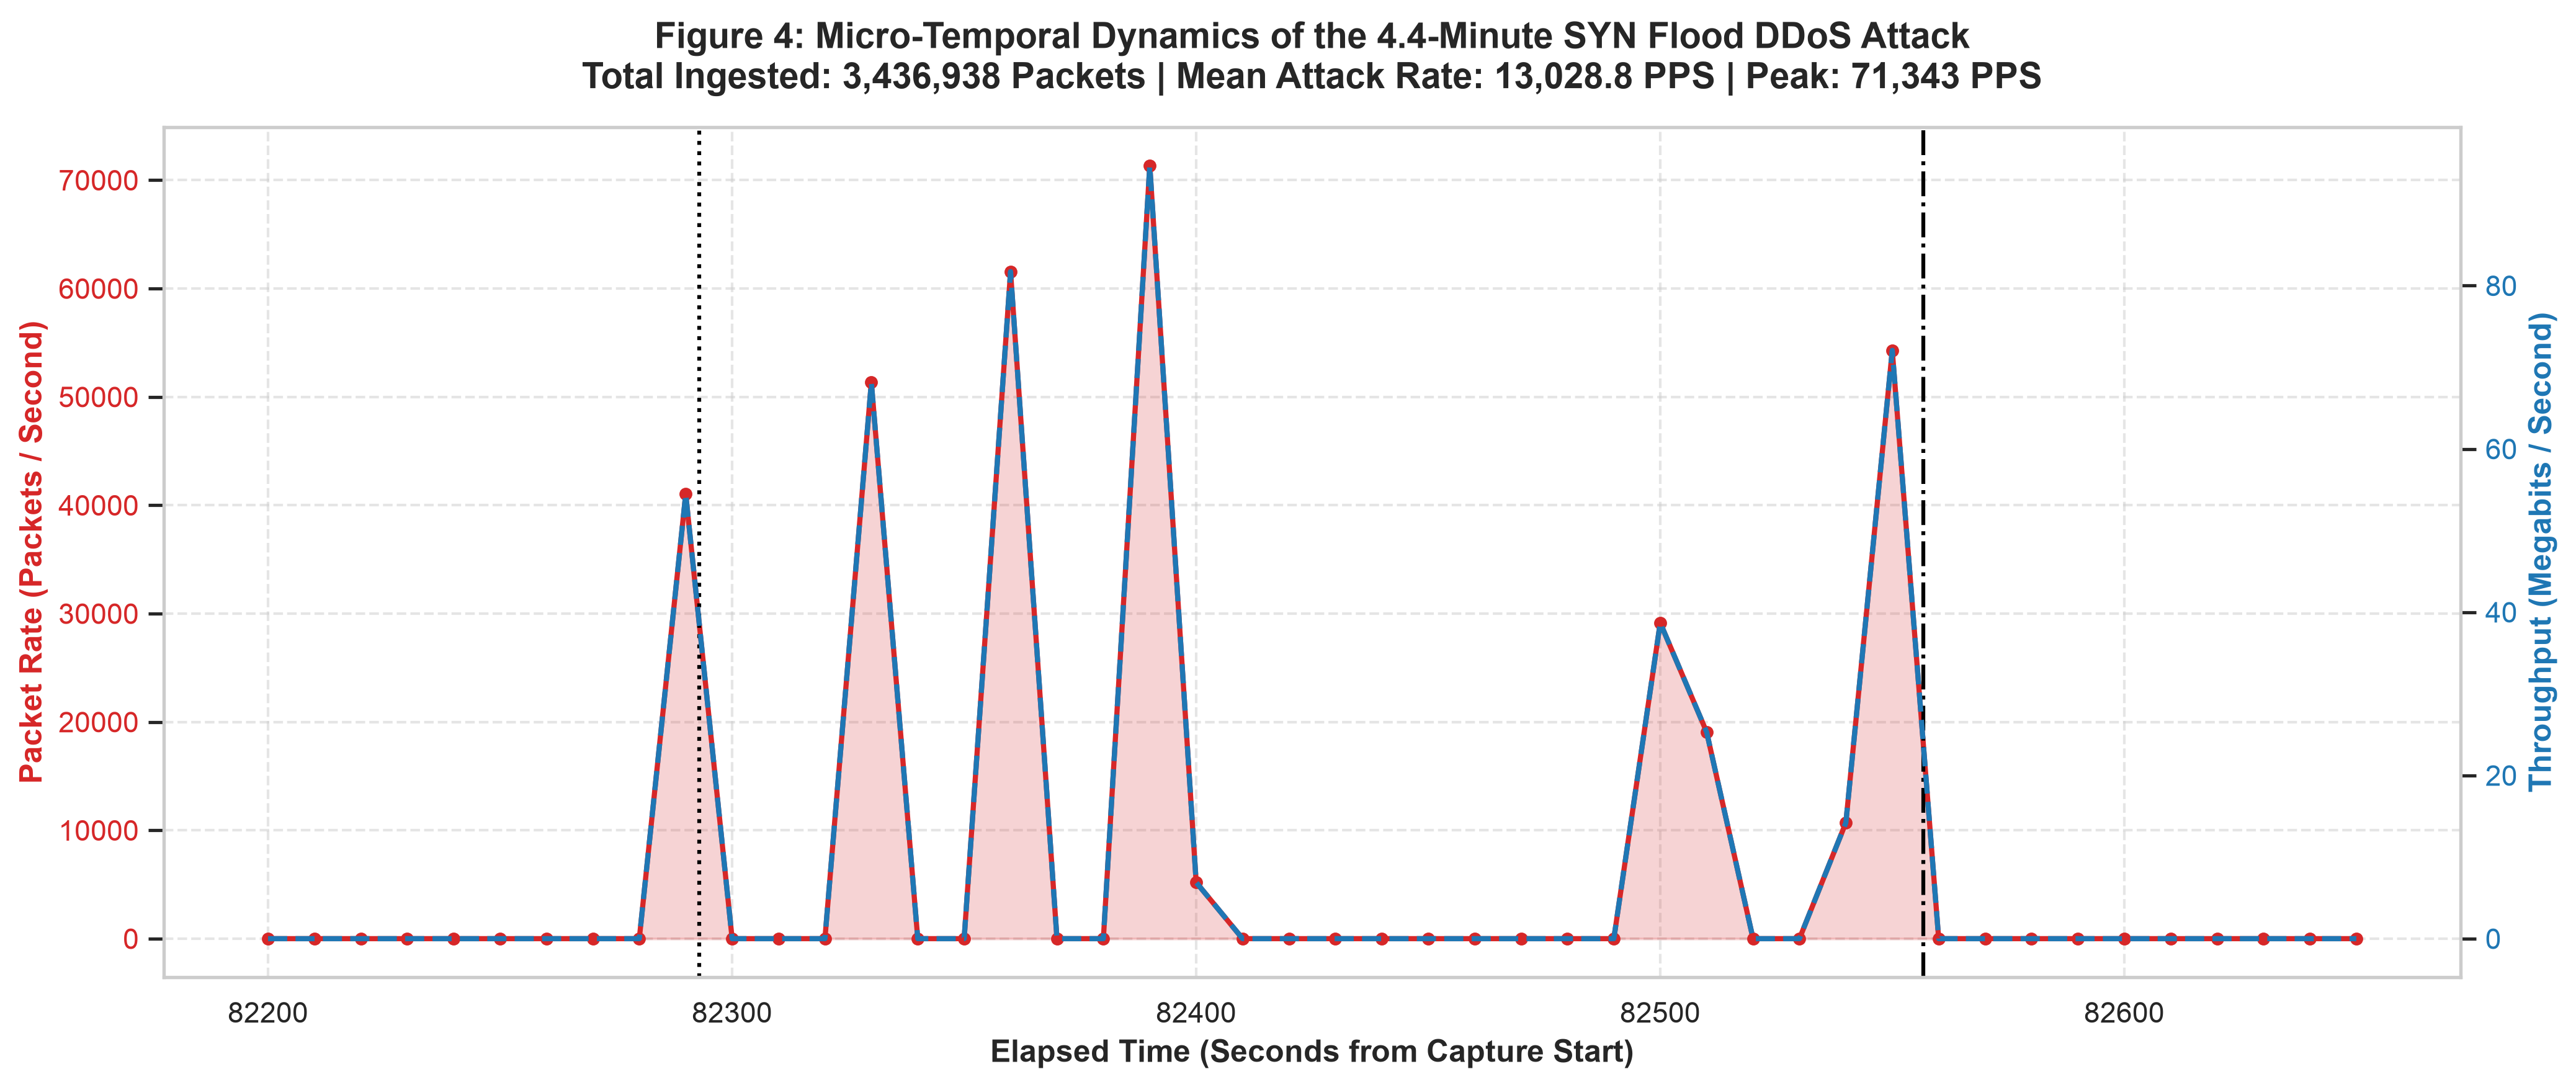

In [9]:
from IPython.display import Image, display

figures = [
    'fig01_protocol_distribution.png',
    'fig02_packet_length_distribution.png',
    'fig03_traffic_volume_timeseries.png',
    'fig04_ddos_flood_zoom.png',
    'fig05_top_endpoints_matrix.png',
    'fig06_port_distribution.png',
    'fig07_tcp_flag_distribution.png',
    'fig08_packet_size_by_protocol_boxplots.png',
    'fig09_correlation_heatmap.png',
    'fig10_outlier_analysis_length_ttl.png',
    'fig11_temporal_feature_drift.png',
    'fig12_attack_profiles_radar_comparison.png',
    'fig13_inter_arrival_time_distribution.png',
    'fig14_cumulative_traffic_growth.png'
]

for fig_name in figures[:4]: # Display first 4 figures inline
    fig_path = os.path.join(base_dir, 'results', 'figures', fig_name)
    print(f"Displaying {fig_name}:")
    display(Image(filename=fig_path, width=800))


### 10. Research Suitability Assessment for Adaptive ML & Concept Drift

**Evaluation Conclusion:**
1. **Network Anomaly Detection & Volumetric Attack Research:** Highly suitable. The dataset provides realistic Nmap reconnaissance sweeps and an intense 13,000 PPS SYN flood attack with fine-grained microsecond timestamps.
2. **Concept Drift Research:** Partially suitable with strict experimental boundaries. While the dataset exhibits severe covariate shift (PSI > 12.0) across operational windows, this represents attack prevalence shift and synthetic tool burstiness rather than genuine gradual real-world concept drift.
3. **Supervised Multiclass ML:** Requires semi-automated or forensic heuristic labeling. The provided source labels (`Source_Known` and `Destination_Known`) indicate IP subnet membership, NOT ground-truth attack categories.
